<a href="https://colab.research.google.com/github/nicolasrporto/R-Applications/blob/main/Atividade11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#como a escolha da arquitetura do modelo afeta a acurácia do conjunto de teste no caso da classificação dos dígitos do MNIST.
#Considere o exemplo de nossa rede densamente conectada. No exemplo, ela tem 512 neurônios em uma camada oculta.


#inicialize a semente aleatória com seu número USP

set.seed(11322768)
# paralelização
install.packages("doParallel")
install.packages("keras")
install.packages("ggplot2")
library(doParallel)
library(keras)
library(ggplot2)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘foreach’, ‘iterators’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘RcppTOML’, ‘here’, ‘png’, ‘config’, ‘tfautograph’, ‘reticulate’, ‘tensorflow’, ‘tfruns’, ‘zeallot’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Loading required package: foreach

Loading required package: iterators

Loading required package: parallel

The keras package is deprecated. Please use the keras3 package instead.
Alternatively, to continue using legacy keras, call `py_require_legacy_keras()`.



In [ ]:
#varie o número de neurônios em cada camada: use 32 e 64

# dados
mnist <- dataset_mnist()
train_images <- mnist$train$x
train_labels <- mnist$train$y
test_images <- mnist$test$x
test_labels <- mnist$test$y



In [ ]:
# Algo sobre os dados:
dim(train_images)

length(train_labels)

dim(test_images)

length(test_labels)

#summary mostrará os valores dos pixels
summary(train_images[,14,14])

[1] 60000    28    28

[1] 60000

[1] 10000    28    28

[1] 10000

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   0.00    0.00   29.00   96.97  232.00  255.00 

[1] 7 2 1 0 4 1 4 9 5 9

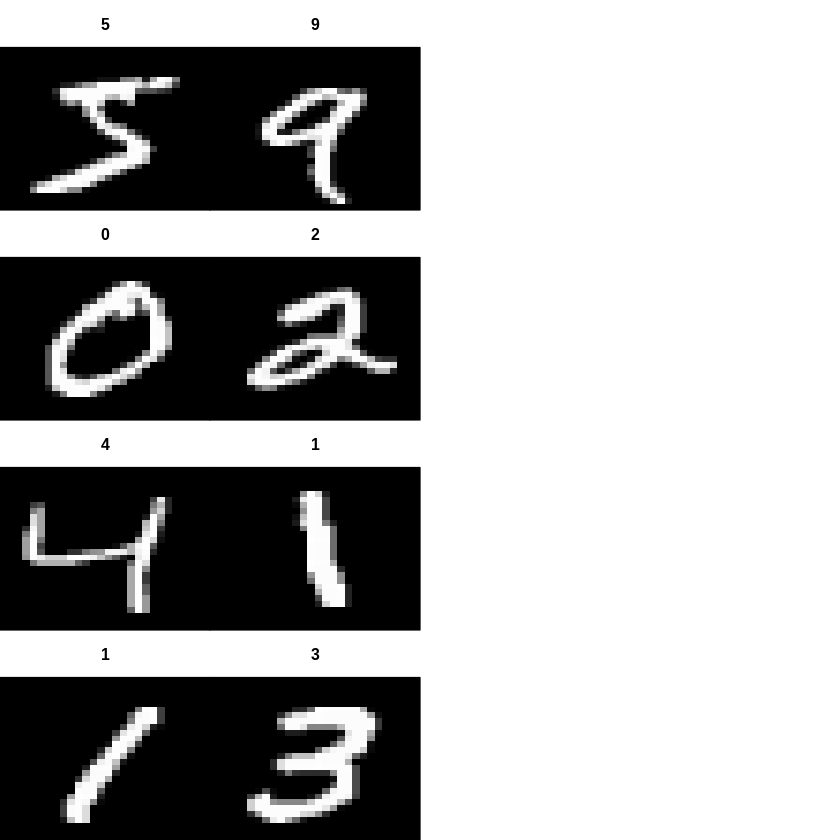

In [ ]:
test_labels[1:10]

par(mfcol=c(4,4))
par(mar=c(0, 0, 3, 0), xaxs='i', yaxs='i')
for (idx in 1:8) {
    im <- train_images[idx,,]
    im <- t(apply(im, 2, rev))
    image(1:28, 1:28, im, col=gray((0:255)/255),
          xaxt='n', main=paste(train_labels[idx]))

}

In [ ]:
# MLP com uma camada oculta com 512 unidades ReLU

#Vamos considerar uma rede densamente conectada com uma camada de entrada com 28x28=784 neurônios (parâmetro ‘input shape’)
#512 numa camada oculta e 10 na camada de saída (uma saida para cada dígito): 784:512:10


#varie o número de neurônios em cada camada: use 32 e 64

modelo32 <- keras_model_sequential() %>%
  layer_dense(units = 32, activation = "relu", input_shape = c(sqrt(32) * sqrt(32))) %>%  #oculta + entrada
  layer_dense(units = 32, activation = "softmax") #saída

modelo64 <- keras_model_sequential() %>%
  layer_dense(units = 64, activation = "relu", input_shape = c(sqrt(64) * sqrt(64))) %>% #oculta
  layer_dense(units = 64, activation = "softmax") #saída


In [ ]:
modelo32 %>% compile(
  optimizer = "rmsprop",                # variante turbinada da descida do gradiente
  loss = "categorical_crossentropy",    # classificação multi-classe
  metrics = c("accuracy")               # classificação
)

# um resumo do modelo:
summary(modelo32)

modelo64 %>% compile(
  optimizer = "rmsprop",                # variante turbinada da descida do gradiente
  loss = "categorical_crossentropy",    # classificação multi-classe
  metrics = c("accuracy")               # classificação
)

# um resumo do modelo:
summary(modelo64)

Model: "sequential_2"
________________________________________________________________________________
 Layer (type)                       Output Shape                    Param #     
 dense_5 (Dense)                    (None, 32)                      1056        
 dense_4 (Dense)                    (None, 32)                      1056        
Total params: 2112 (8.25 KB)
Trainable params: 2112 (8.25 KB)
Non-trainable params: 0 (0.00 Byte)
________________________________________________________________________________
Model: "sequential_3"
________________________________________________________________________________
 Layer (type)                       Output Shape                    Param #     
 dense_7 (Dense)                    (None, 64)                      4160        
 dense_6 (Dense)                    (None, 64)                      4160        
Total params: 8320 (32.50 KB)
Trainable params: 8320 (32.50 KB)
Non-trainable params: 0 (0.00 Byte)
_____________________________

In [ ]:
# MLP com duas camadas ocultas
modelo2 <- keras_model_sequential() %>%
  layer_dense(units = 64, activation = "relu", input_shape = c(sqrt(64) * sqrt(64))) %>%  #oculta + entrada
  layer_dense(units = 64, activation = "relu") %>% #oculta
  layer_dense(units = 64, activation = "softmax") #saída

In [ ]:
# MLP com duas camadas ocultsa com 512 unidades ReLU
modelo3 <- keras_model_sequential() %>%
  layer_dense(units = 512, activation = "relu", input_shape = c(sqrt(64) * sqrt(64))) %>% #oculta
  layer_dense(units = 64, activation = "relu") %>% #oculta
  layer_dense(units = 64, activation = "relu") %>% #oculta
  layer_dense(units = 64, activation = "softmax") #saída

In [ ]:
modelo2 %>% compile(
  optimizer = "rmsprop",                # variante turbinada da descida do gradiente
  loss = "categorical_crossentropy",    # classificação multi-classe
  metrics = c("accuracy")               # classificação
)

# um resumo do modelo:
summary(modelo2)

modelo3 %>% compile(
  optimizer = "rmsprop",                # variante turbinada da descida do gradiente
  loss = "categorical_crossentropy",    # classificação multi-classe
  metrics = c("accuracy")               # classificação
)

# um resumo do modelo:
summary(modelo3)

Model: "sequential_4"
________________________________________________________________________________
 Layer (type)                       Output Shape                    Param #     
 dense_10 (Dense)                   (None, 64)                      4160        
 dense_9 (Dense)                    (None, 64)                      4160        
 dense_8 (Dense)                    (None, 64)                      4160        
Total params: 12480 (48.75 KB)
Trainable params: 12480 (48.75 KB)
Non-trainable params: 0 (0.00 Byte)
________________________________________________________________________________
Model: "sequential_5"
________________________________________________________________________________
 Layer (type)                       Output Shape                    Param #     
 dense_14 (Dense)                   (None, 512)                     33280       
 dense_13 (Dense)                   (None, 64)                      32832       
 dense_12 (Dense)                   (None, 6

In [ ]:
#varie a ativação no modelo com uma camada com 512 neurônios: compare ReLU com tanh


modelorelu <- keras_model_sequential() %>%
  layer_dense(units = 512, activation = "relu", input_shape = c(28 * 28)) %>%
  layer_dense(units = 64, activation = "relu") %>% #oculta
  layer_dense(units = 10, activation = "softmax")

modelotanh <- keras_model_sequential() %>%
  layer_dense(units = 512, activation = "relu", input_shape = c(28 * 28)) %>%
  layer_dense(units = 64, activation = "tanh") %>% #oculta
  layer_dense(units = 10, activation = "softmax")


In [ ]:
modelorelu %>% compile(
  optimizer = "rmsprop",                # variante turbinada da descida do gradiente
  loss = "categorical_crossentropy",    # classificação multi-classe
  metrics = c("accuracy")               # classificação
)

# um resumo do modelo:
summary(modelorelu)

modelotanh %>% compile(
  optimizer = "rmsprop",                # variante turbinada da descida do gradiente
  loss = "categorical_crossentropy",    # classificação multi-classe
  metrics = c("accuracy")               # classificação
)

# um resumo do modelo:
summary(modelotanh)

Model: "sequential_6"
________________________________________________________________________________
 Layer (type)                       Output Shape                    Param #     
 dense_17 (Dense)                   (None, 512)                     401920      
 dense_16 (Dense)                   (None, 64)                      32832       
 dense_15 (Dense)                   (None, 10)                      650         
Total params: 435402 (1.66 MB)
Trainable params: 435402 (1.66 MB)
Non-trainable params: 0 (0.00 Byte)
________________________________________________________________________________
Model: "sequential_7"
________________________________________________________________________________
 Layer (type)                       Output Shape                    Param #     
 dense_20 (Dense)                   (None, 512)                     401920      
 dense_19 (Dense)                   (None, 64)                      32832       
 dense_18 (Dense)                   (None, 1

In [ ]:
# pré-processamento do conjunto de treino
dim(train_images)

# muda o formato do arquivo train_images para o keras entender
train_images <- array_reshape(train_images, c(60000, 28 * 28))

dim(train_images)

# agora cada imagem é representada por um vetor com 784 valores de pixels

# divide-se os valores dos pixels por 255 para ficarem entre 0 e 1
min(train_images)

max(train_images)

train_images <- train_images / 255

# pré-processamento do conjunto de teste
test_images <- array_reshape(test_images, c(10000, 28 * 28))
test_images <- test_images / 255

train_labels <- to_categorical(train_labels)
test_labels <- to_categorical(test_labels)

# as classes são 'hot-coded': todas 0, exceto uma (o target) que é 1:
head(train_labels)



[1] 60000    28    28

[1] 60000   784

[1] 0

[1] 255

0,0,0,0,0,1,0,0,0,0
1,0,0,0,0,0,0,0,0,0
0,0,0,0,1,0,0,0,0,0
0,1,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,1
0,0,1,0,0,0,0,0,0,0


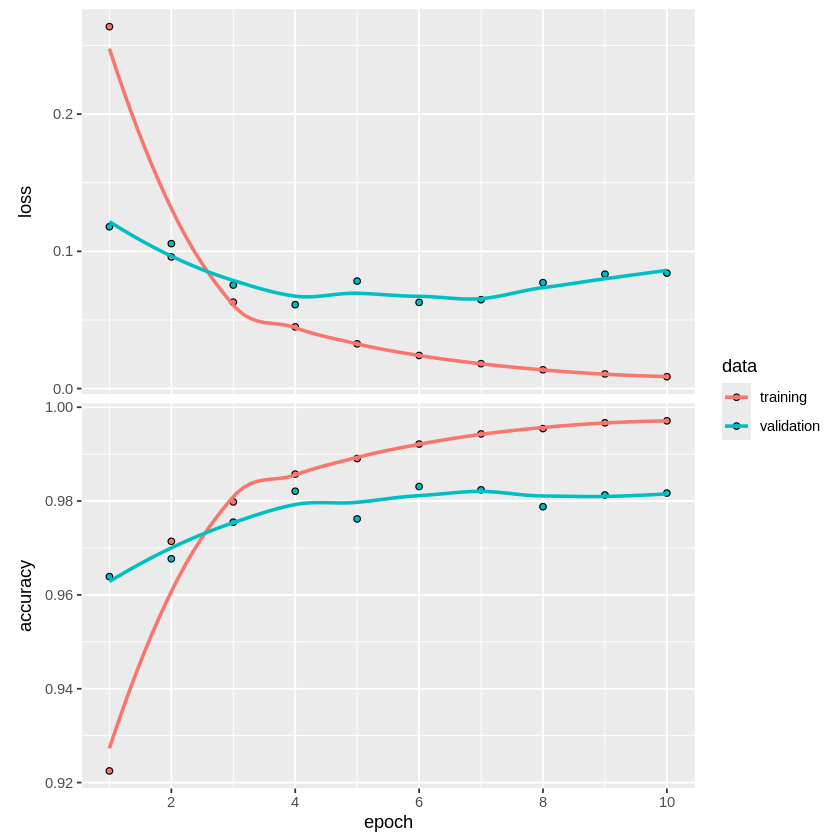

In [ ]:


t0 = Sys.time()
historia <- modelorelu %>% fit(train_images, train_labels, epochs = 10, batch_size = 128,verbose=0,validation_data = list(test_images,test_labels))
plot(historia)

In [ ]:
Sys.time()-t0
metrics <- modelorelu %>% evaluate(test_images, test_labels, verbose = 0)
metrics

In [ ]:
#feito pro relu, agora falta tanh